In [1]:
print('hola')

hola


Dataset de retornos logarítmicos de las 30 empresas:

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np

djia_tickers = [
    "AAPL", "AMGN", "AXP", "BA", "CAT", "CRM", "CSCO", "CVX", "DIS", 
    "GS", "HD", "HON", "IBM", "INTC", "JNJ", "JPM", "KO", "MCD", "MMM",
    "MRK", "MSFT", "NKE", "PG", "TRV", "UNH", "V", "VZ", "WMT", "AMZN"
]

print("Descargando precios...")
datos = yf.download(djia_tickers, start="2008-03-20", interval="1d")
# Extracción robusta de los precios de cierre
try:
    # Intenta buscar en el primer nivel (comportamiento clásico)
    precios = datos['Adj Close']
except KeyError:
    try:
        # Intenta buscar en el segundo nivel usando cross-section (comportamiento nuevo)
        precios = datos.xs('Adj Close', level=1, axis=1)
    except KeyError:
        # Fallback por si la métrica fue renombrada simplemente a 'Close'
        try:
            precios = datos['Close']
        except KeyError:
            precios = datos.xs('Close', level=1, axis=1)

# 1. Eliminamos acciones que no existían hace 15 años (ej. si tienen más de 10 NaNs)
precios = precios.dropna(axis=1, thresh=len(precios) - 10)

# 2. Calculamos retornos logarítmicos
retornos_log = np.log(precios / precios.shift(1))

# 3. Borramos días aislados con fallos
retornos_log = retornos_log.dropna(axis=0, how='any')

print(f"Dimensiones finales: {retornos_log.shape[0]} días, {retornos_log.shape[1]} acciones.")
retornos_log.to_csv("retornos_log_djia_18y.csv")
print("Archivo 'retornos_log_djia_18y.csv' generado con éxito.")

Descargando precios...


[*********************100%***********************]  29 of 29 completed

Dimensiones finales: 4683 días, 29 acciones.
Archivo 'retornos_log_djia_15y.csv' generado con éxito.


csv de la volatilidad:

In [2]:
import pandas as pd
import numpy as np

# 1. Cargás los datos crudos (tu CSV actual)
retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)

# 2. Retorno diario del mercado (promedio de todas las acciones)
r_mercado = retornos.mean(axis=1)

# 3. Calculás la volatilidad (desviación estándar a 5 días) y la desplazás hacia "atrás"
vol_futura_5d = r_mercado.rolling(window=5).std().shift(-5)

# Las últimas 5 filas van a dar NaN porque no tienen 5 días de futuro para calcular
vol_futura_5d = vol_futura_5d.dropna()

# Este objeto 'vol_futura_5d' es tu variable a predecir (y) en formato continuo.
print(vol_futura_5d.head())

vol_futura_5d.to_csv("volatilidad.csv")

Date
2008-03-24    0.008321
2008-03-25    0.019222
2008-03-26    0.018510
2008-03-27    0.015884
2008-03-28    0.015166
dtype: float64


cvs de features financieras clásicas:

In [4]:
import pandas as pd

# 1. Cargar los retornos limpios
retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)

# 2. Calcular el retorno diario del mercado (promedio de las 29 acciones)
r_mercado = retornos.mean(axis=1)

# 3. Crear un DataFrame vacío con el mismo índice temporal para guardar las features
df_features = pd.DataFrame(index=retornos.index)
ventana = 30

# 4. Calcular las features financieras rodantes (rolling)
df_features['retorno_medio_30d'] = r_mercado.rolling(window=ventana).mean()
df_features['volatilidad_30d'] = r_mercado.rolling(window=ventana).std()
df_features['momento_30d'] = r_mercado.rolling(window=ventana).sum()
df_features['caida_maxima_30d'] = r_mercado.rolling(window=ventana).min()

# 5. Limpieza de bordes: Los primeros 29 días dan NaN porque la ventana no está llena
df_features = df_features.dropna()

# 6. Guardar la matriz X del baseline
df_features.to_csv("features_financieras_basicas.csv")

print(f"Dataset de features clásicas generado.")
print(f"Dimensiones: {df_features.shape[0]} filas x {df_features.shape[1]} columnas")
print(df_features.head())

Dataset de features clásicas generado.
Dimensiones: 4654 filas x 4 columnas
            retorno_medio_30d  volatilidad_30d  momento_30d  caida_maxima_30d
Date                                                                         
2008-05-02           0.002506         0.011507     0.075168         -0.021044
2008-05-05           0.001855         0.011330     0.055647         -0.021044
2008-05-06           0.001918         0.011337     0.057541         -0.021044
2008-05-07           0.001734         0.011588     0.052012         -0.021044
2008-05-08           0.002226         0.011158     0.066774         -0.021044


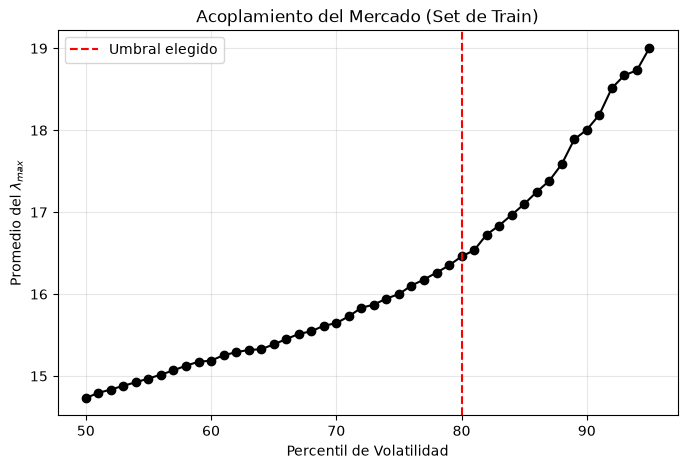

In [6]:
import matplotlib.pyplot as plt
import numpy as np

retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)

# Si no tenés el lambda_max en X_train, descomentá esto para calcularlo (toma unos segundos):
retornos_train = retornos.loc[vol_train.index]
corrs = retornos_train.rolling(window=21).corr().dropna(how='all') # ventana típica de 1 mes
lambda_max_train = corrs.groupby(level=0).apply(lambda x: np.linalg.eigvalsh(x.values)[-1])

# Si ya lo tenés en tus features, usá directamente tu columna (ajustá el nombre):
#lambda_max_train = X_train['lambda_max'] 

percentiles = np.arange(50, 96, 1)
promedios_lambda = []

for p in percentiles:
    umbral_p = np.percentile(vol_train, p)
    # Filtramos los días donde la volatilidad supera el percentil p
    mascara = vol_train >= umbral_p
    # Calculamos el lambda_max promedio de ese régimen
    promedio = lambda_max_train[mascara].mean()
    promedios_lambda.append(promedio)

# Graficamos la transición de fase
plt.figure(figsize=(8, 5))
plt.plot(percentiles, promedios_lambda, marker='o', linestyle='-', color='black')
plt.title('Acoplamiento del Mercado (Set de Train)')
plt.xlabel('Percentil de Volatilidad')
plt.ylabel('Promedio del $\lambda_{max}$')
plt.grid(True, alpha=0.3)

# Podés agregar una línea vertical provisoria donde a ojo veas el codo
plt.axvline(x=80, color='red', linestyle='--', label='Umbral elegido')
plt.legend()

plt.show()

Split

In [4]:
import pandas as pd
import numpy as np

# 1. Cargás tus features (X) y asumimos que ya tenés vol_futura_5d calculada
X = pd.read_csv("features_financieras_basicas.csv", index_col=0, parse_dates=True)

vol_futura_5d = pd.read_csv("volatilidad.csv", index_col=0, parse_dates=True)

# 2. Las unimos en un único DataFrame para alinearlas por fecha
df_completo = X.copy()
df_completo['target_continuo'] = vol_futura_5d

# 3. Purga maestra: elimina filas donde falte X (por ej. medias móviles iniciales) 
# o falte y (los últimos 5 días que no tienen futuro). 
# Esto garantiza que X e y tengan exactamente la misma cantidad de filas.
df_completo = df_completo.dropna()

print(f"Filas limpias y alineadas: {len(df_completo)}")

# 4. Separamos de nuevo en X e y ya perfectamente alineados
X_alineado = df_completo.drop(columns=['target_continuo'])
y_alineado = df_completo['target_continuo']

# 5. Definimos los cortes y el horizonte de purga
total_filas = len(df_completo)
corte_1 = int(total_filas * 0.70)
corte_2 = int(total_filas * 0.85)
horizonte = 5  # Días de gap para evitar filtración de datos (data leakage)

# 6. Aplicamos los cortes cronológicos con el horizonte de seguridad

# Train: frenamos 5 días antes del corte_1 para no pisar el futuro de Validation
X_train = X_alineado.iloc[:corte_1 - horizonte]
vol_train = y_alineado.iloc[:corte_1 - horizonte]

# Validation: arranca en corte_1 y frena 5 días antes de corte_2
X_val = X_alineado.iloc[corte_1 : corte_2 - horizonte]
vol_val = y_alineado.iloc[corte_1 : corte_2 - horizonte]

# Test: arranca limpio en corte_2 hasta el final
X_test = X_alineado.iloc[corte_2:]
vol_test = y_alineado.iloc[corte_2:]

# 7. Calculamos el umbral SOLO con el set de Train ya purgado
umbral = np.percentile(vol_train, 75)

# 8. Binarizamos los tres sets usando ese umbral
y_train = (vol_train > umbral).astype(int)
y_val   = (vol_val > umbral).astype(int)
y_test  = (vol_test > umbral).astype(int)

Filas limpias y alineadas: 4649


Entreno del modelo VSM y métricas:

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, 
    average_precision_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix,
    balanced_accuracy_score
)

# 1. Escalado OBLIGATORIO
# .fit_transform() SOLO en train para no filtrar información del futuro
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 2. Definición y entrenamiento
# kernel='rbf': Permite separar datos con fronteras no lineales (curvas).
# probability=True: Obligatorio para poder calcular la métrica ROC-AUC.
# class_weight='balanced': Penaliza al modelo 4 veces más si se equivoca en un "1" 
#                          para compensar la relación 80/20 de tus datos.
svm_model = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 3. Predicciones
y_pred = svm_model.predict(X_val_scaled) # Devuelve clase dura (0 o 1)
y_prob = svm_model.predict_proba(X_val_scaled)[:, 1] # Devuelve probabilidad (0.0 a 1.0)

# 4. Evaluación de Métricas
print("--- MÉTRICAS SOBRE EL SET DE val aisaldo ---")
print("--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---\n")
print(f"ROC-AUC (Global):          {roc_auc_score(y_val, y_prob):.4f}\n")
print(f"PR-AUC (Foco en clase 1):  {average_precision_score(y_val, y_prob):.4f}\n")
print(f"Precision (Alarma real):   {precision_score(y_val, y_pred):.4f}\n")
print(f"Recall (Crisis atrapadas): {recall_score(y_val, y_pred):.4f}\n")
print(f"F1-Score (Clase 1):        {f1_score(y_val, y_pred):.4f}\n")
print(f"Balanced Accuracy:         {balanced_accuracy_score(y_val, y_pred):.4f}")

print("Matriz de Confusión:")
print(confusion_matrix(y_val, y_pred))

c:\Users\tocha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- MÉTRICAS SOBRE EL SET DE val aisaldo ---
--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---

ROC-AUC (Global):          0.7613

PR-AUC (Foco en clase 1):  0.4453

Precision (Alarma real):   0.5128

Recall (Crisis atrapadas): 0.5594

F1-Score (Clase 1):        0.5351

Balanced Accuracy:         0.7105
Matriz de Confusión:
[[473  76]
 [ 63  80]]


In [7]:
import pandas as pd
import numpy as np
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.stats import entropy

# 1. Cargar los retornos limpios (filas: fechas, columnas: 29 empresas)
retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)
valores = retornos.values
fechas = retornos.index
n_dias, n_empresas = valores.shape
ventana = 30

# Listas para guardar las features
lambda_max_norm = []
mst_distancia_media = []
entropia_shannon = []
hurst_local = []

# Retardos (lags) para estimar Hurst dentro de una ventana de 30 días
lags = np.array([1, 2, 4, 8])
log_lags = np.log(lags)

# 2. Barrido por ventana móvil (empezamos cuando se llena la primera ventana de 30)
for t in range(ventana - 1, n_dias):
    W = valores[t - ventana + 1 : t + 1, :]  # Submatriz de (30 x 29)
    
    # --- A. Matriz de Correlación y Autovalor Máximo ---
    corr = np.corrcoef(W, rowvar=False)
    # Limpiamos posibles errores numéricos en los bordes [-1, 1]
    corr = np.clip(corr, -1.0, 1.0)
    
    # eigvalsh es exacto y más rápido para matrices simétricas
    autovalores = np.linalg.eigvalsh(corr)
    # Fracción de varianza absorbida por el modo colectivo (entre 1/29 y 1.0)
    lambda_max_norm.append(autovalores[-1] / n_empresas)
    
    # --- B. Árbol de Expansión Mínima (MST) con distancia de Mantegna ---
    dist_matrix = np.sqrt(np.maximum(0.0, 2.0 * (1.0 - corr)))
    mst = minimum_spanning_tree(dist_matrix)
    # Promedio de los (N - 1) enlaces del árbol
    mst_distancia_media.append(mst.sum() / (n_empresas - 1))
    
    # --- C. Entropía de Shannon (sobre forma de distribución, sin efecto escala) ---
    W_plana = W.ravel()  # 870 observaciones (30 días x 29 empresas)
    W_std = (W_plana - np.mean(W_plana)) / (np.std(W_plana) + 1e-8)
    conteos, _ = np.histogram(W_std, bins=20, range=(-4, 4), density=False)
    # Calculamos entropía en base natural (nats)
    entropia_shannon.append(entropy(conteos + 1e-10))
    
    # --- D. Exponente de Hurst Generalizado (escalamiento de varianza) ---
    # Precios logarítmicos acumulados dentro de la ventana para las 29 empresas
    perfil = np.cumsum(W - np.mean(W, axis=0), axis=0)
    var_por_lag = [
        np.mean(np.var(perfil[lag:] - perfil[:-lag], axis=0))
        for lag in lags
    ]
    # Como Var(tau) ~ tau^(2H), la pendiente en log-log dividida por 2 es H
    pendiente, _ = np.polyfit(log_lags, np.log(np.array(var_por_lag) + 1e-12), 1)
    hurst_local.append(pendiente / 2.0)

# 3. Armar el DataFrame alineado con las fechas correspondientes
df_fisicas = pd.DataFrame({
    'lambda_max_norm': lambda_max_norm,
    'mst_distancia_media': mst_distancia_media,
    'entropia_shannon': entropia_shannon,
    'hurst_30d': hurst_local
}, index=fechas[ventana - 1:])

# 4. Guardar en CSV
df_fisicas.to_csv("features_fisicas.csv")

print(f"CSV generado con éxito: {df_fisicas.shape[0]} filas x {df_fisicas.shape[1]} columnas.")
print(df_fisicas.head())

CSV generado con éxito: 4654 filas x 4 columnas.
            lambda_max_norm  mst_distancia_media  entropia_shannon  hurst_30d
Date                                                                         
2008-05-02         0.407633             0.838624          2.185042   0.368897
2008-05-05         0.407895             0.840241          2.185722   0.370184
2008-05-06         0.407672             0.839267          2.183601   0.376185
2008-05-07         0.414823             0.834241          2.191956   0.375894
2008-05-08         0.402626             0.842901          2.188670   0.373362


In [8]:
import pandas as pd
import numpy as np

# 1. Cargás tus features (X) y asumimos que ya tenés vol_futura_5d calculada
X = pd.read_csv("features_fisicas.csv", index_col=0, parse_dates=True)

vol_futura_5d = pd.read_csv("volatilidad.csv", index_col=0, parse_dates=True)

# 2. Las unimos en un único DataFrame para alinearlas por fecha
df_completo = X.copy()
df_completo['target_continuo'] = vol_futura_5d

# 3. Purga maestra: elimina filas donde falte X (por ej. medias móviles iniciales) 
# o falte y (los últimos 5 días que no tienen futuro). 
# Esto garantiza que X e y tengan exactamente la misma cantidad de filas.
df_completo = df_completo.dropna()

print(f"Filas limpias y alineadas: {len(df_completo)}")

# 4. Separamos de nuevo en X e y ya perfectamente alineados
X_alineado = df_completo.drop(columns=['target_continuo'])
y_alineado = df_completo['target_continuo']

# 5. Definimos los cortes y el horizonte de purga
total_filas = len(df_completo)
corte_1 = int(total_filas * 0.70)
corte_2 = int(total_filas * 0.85)
horizonte = 5  # Días de gap para evitar filtración de datos (data leakage)

# 6. Aplicamos los cortes cronológicos con el horizonte de seguridad

# Train: frenamos 5 días antes del corte_1 para no pisar el futuro de Validation
X_train = X_alineado.iloc[:corte_1 - horizonte]
vol_train = y_alineado.iloc[:corte_1 - horizonte]

# Validation: arranca en corte_1 y frena 5 días antes de corte_2
X_val = X_alineado.iloc[corte_1 : corte_2 - horizonte]
vol_val = y_alineado.iloc[corte_1 : corte_2 - horizonte]

# Test: arranca limpio en corte_2 hasta el final
X_test = X_alineado.iloc[corte_2:]
vol_test = y_alineado.iloc[corte_2:]

# 7. Calculamos el umbral SOLO con el set de Train ya purgado
umbral = np.percentile(vol_train, 75)

# 8. Binarizamos los tres sets usando ese umbral
y_train = (vol_train > umbral).astype(int)
y_val   = (vol_val > umbral).astype(int)
y_test  = (vol_test > umbral).astype(int)

Filas limpias y alineadas: 4649


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, 
    average_precision_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix,
    balanced_accuracy_score
)

# 1. Escalado OBLIGATORIO
# .fit_transform() SOLO en train para no filtrar información del futuro
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 2. Definición y entrenamiento
# kernel='rbf': Permite separar datos con fronteras no lineales (curvas).
# probability=True: Obligatorio para poder calcular la métrica ROC-AUC.
# class_weight='balanced': Penaliza al modelo 4 veces más si se equivoca en un "1" 
#                          para compensar la relación 80/20 de tus datos.
svm_model = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 3. Predicciones
y_pred = svm_model.predict(X_val_scaled) # Devuelve clase dura (0 o 1)
y_prob = svm_model.predict_proba(X_val_scaled)[:, 1] # Devuelve probabilidad (0.0 a 1.0)

# 4. Evaluación de Métricas
print("--- MÉTRICAS SOBRE EL SET DE val aisaldo ---")
print("--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---\n")
print(f"ROC-AUC (Global):          {roc_auc_score(y_val, y_prob):.4f}\n")
print(f"PR-AUC (Foco en clase 1):  {average_precision_score(y_val, y_prob):.4f}\n")
print(f"Precision (Alarma real):   {precision_score(y_val, y_pred):.4f}\n")
print(f"Recall (Crisis atrapadas): {recall_score(y_val, y_pred):.4f}\n")
print(f"F1-Score (Clase 1):        {f1_score(y_val, y_pred):.4f}\n")
print(f"Balanced Accuracy:         {balanced_accuracy_score(y_val, y_pred):.4f}")

print("Matriz de Confusión:")
print(confusion_matrix(y_val, y_pred))

c:\Users\tocha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- MÉTRICAS SOBRE EL SET DE val aisaldo ---
--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---

ROC-AUC (Global):          0.7082

PR-AUC (Foco en clase 1):  0.4373

Precision (Alarma real):   0.4211

Recall (Crisis atrapadas): 0.4476

F1-Score (Clase 1):        0.4339

Balanced Accuracy:         0.6436
Matriz de Confusión:
[[461  88]
 [ 79  64]]


In [12]:
df_features = pd.read_csv("features_financieras_basicas.csv", index_col=0, parse_dates=True)
df_fisicas = pd.read_csv("features_fisicas.csv", index_col=0, parse_dates=True)

# 1. Unir baseline financiero + features físicas por fecha
X = pd.concat([df_features.drop(columns=['retorno_medio_30d']), df_fisicas], axis=1)

vol_futura_5d = pd.read_csv("volatilidad.csv", index_col=0, parse_dates=True)

# 2. Las unimos en un único DataFrame para alinearlas por fecha
df_completo = X.copy()
df_completo['target_continuo'] = vol_futura_5d

# 3. Purga maestra: elimina filas donde falte X (por ej. medias móviles iniciales) 
# o falte y (los últimos 5 días que no tienen futuro). 
# Esto garantiza que X e y tengan exactamente la misma cantidad de filas.
df_completo = df_completo.dropna()

print(f"Filas limpias y alineadas: {len(df_completo)}")

# 4. Separamos de nuevo en X e y ya perfectamente alineados
X_alineado = df_completo.drop(columns=['target_continuo'])
y_alineado = df_completo['target_continuo']

# 5. Definimos los cortes y el horizonte de purga
total_filas = len(df_completo)
corte_1 = int(total_filas * 0.70)
corte_2 = int(total_filas * 0.85)
horizonte = 5  # Días de gap para evitar filtración de datos (data leakage)

# 6. Aplicamos los cortes cronológicos con el horizonte de seguridad

# Train: frenamos 5 días antes del corte_1 para no pisar el futuro de Validation
X_train = X_alineado.iloc[:corte_1 - horizonte]
vol_train = y_alineado.iloc[:corte_1 - horizonte]

# Validation: arranca en corte_1 y frena 5 días antes de corte_2
X_val = X_alineado.iloc[corte_1 : corte_2 - horizonte]
vol_val = y_alineado.iloc[corte_1 : corte_2 - horizonte]

# Test: arranca limpio en corte_2 hasta el final
X_test = X_alineado.iloc[corte_2:]
vol_test = y_alineado.iloc[corte_2:]

# 7. Calculamos el umbral SOLO con el set de Train ya purgado
umbral = np.percentile(vol_train, 75)

# 8. Binarizamos los tres sets usando ese umbral
y_train = (vol_train > umbral).astype(int)
y_val   = (vol_val > umbral).astype(int)
y_test  = (vol_test > umbral).astype(int)

Filas limpias y alineadas: 4649


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, 
    average_precision_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix,
    balanced_accuracy_score
)

# 1. Escalado OBLIGATORIO
# .fit_transform() SOLO en train para no filtrar información del futuro
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 2. Definición y entrenamiento
# kernel='rbf': Permite separar datos con fronteras no lineales (curvas).
# probability=True: Obligatorio para poder calcular la métrica ROC-AUC.
# class_weight='balanced': Penaliza al modelo 4 veces más si se equivoca en un "1" 
#                          para compensar la relación 80/20 de tus datos.
svm_model = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 3. Predicciones
y_pred = svm_model.predict(X_val_scaled) # Devuelve clase dura (0 o 1)
y_prob = svm_model.predict_proba(X_val_scaled)[:, 1] # Devuelve probabilidad (0.0 a 1.0)

# 4. Evaluación de Métricas
print("--- MÉTRICAS SOBRE EL SET DE val aisaldo ---")
print("--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---\n")
print(f"ROC-AUC (Global):          {roc_auc_score(y_val, y_prob):.4f}\n")
print(f"PR-AUC (Foco en clase 1):  {average_precision_score(y_val, y_prob):.4f}\n")
print(f"Precision (Alarma real):   {precision_score(y_val, y_pred):.4f}\n")
print(f"Recall (Crisis atrapadas): {recall_score(y_val, y_pred):.4f}\n")
print(f"F1-Score (Clase 1):        {f1_score(y_val, y_pred):.4f}\n")
print(f"Balanced Accuracy:         {balanced_accuracy_score(y_val, y_pred):.4f}")

print("Matriz de Confusión:")
print(confusion_matrix(y_val, y_pred))

c:\Users\tocha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- MÉTRICAS SOBRE EL SET DE val aisaldo ---
--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---

ROC-AUC (Global):          0.7298

PR-AUC (Foco en clase 1):  0.4599

Precision (Alarma real):   0.3684

Recall (Crisis atrapadas): 0.6364

F1-Score (Clase 1):        0.4667

Balanced Accuracy:         0.6761
Matriz de Confusión:
[[393 156]
 [ 52  91]]


In [15]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

cols_base = ['volatilidad_30d', 'momento_30d', 'caida_maxima_30d']
cols_fisicas = ['lambda_max_norm', 'mst_distancia_media', 'entropia_shannon', 'hurst_30d']

# 1. Evaluamos el baseline puro (las 3 financieras)
scaler = StandardScaler()
svm = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)

X_tr_base = scaler.fit_transform(X_train[cols_base])
X_va_base = scaler.transform(X_val[cols_base])
svm.fit(X_tr_base, y_train)
prob_base = svm.predict_proba(X_va_base)[:, 1]
pred_base = svm.predict(X_va_base)

print(f"{'Combinación':<35} | {'ROC-AUC':<8} | {'PR-AUC':<8} | {'F1 (C1)':<8} | {'FP':<4} | {'VP':<4}")
print("-" * 78)
tn, fp, fn, vp = confusion_matrix(y_val, pred_base).ravel()
print(f"{'Baseline (3 financieras)':<35} | {roc_auc_score(y_val, prob_base):.4f}   | {average_precision_score(y_val, prob_base):.4f}   | {f1_score(y_val, pred_base):.4f}   | {fp:<4} | {vp:<4}")

# 2. Probamos agregando UNA variable física a la vez
for col in cols_fisicas:
    cols_test = cols_base + [col]
    X_tr = scaler.fit_transform(X_train[cols_test])
    X_va = scaler.transform(X_val[cols_test])
    
    svm.fit(X_tr, y_train)
    prob = svm.predict_proba(X_va)[:, 1]
    pred = svm.predict(X_va)
    tn, fp, fn, vp = confusion_matrix(y_val, pred).ravel()
    
    print(f"{'Baseline + ' + col:<35} | {roc_auc_score(y_val, prob):.4f}   | {average_precision_score(y_val, prob):.4f}   | {f1_score(y_val, pred):.4f}   | {fp:<4} | {vp:<4}")

Combinación                         | ROC-AUC  | PR-AUC   | F1 (C1)  | FP   | VP  
------------------------------------------------------------------------------
Baseline (3 financieras)            | 0.7631   | 0.4670   | 0.5324   | 72   | 78  
Baseline + lambda_max_norm          | 0.7369   | 0.4432   | 0.5016   | 96   | 80  
Baseline + mst_distancia_media      | 0.7460   | 0.4638   | 0.5034   | 80   | 75  
Baseline + entropia_shannon         | 0.7547   | 0.4663   | 0.5139   | 71   | 74  
Baseline + hurst_30d                | 0.7625   | 0.4478   | 0.5508   | 78   | 84  


In [16]:
# 1. Creamos las derivadas temporales (cuánto se contrajo la red en los últimos 5 días)
df_fisicas_dinamicas = pd.DataFrame(index=df_fisicas.index)
df_fisicas_dinamicas['hurst_30d'] = df_fisicas['hurst_30d']
df_fisicas_dinamicas['d_lambda_5d'] = df_fisicas['lambda_max_norm'].diff(5)
df_fisicas_dinamicas['d_mst_5d'] = df_fisicas['mst_distancia_media'].diff(5)
df_fisicas_dinamicas['d_entropia_5d'] = df_fisicas['entropia_shannon'].diff(5)

# 2. Unimos con las 3 financieras del baseline y alineamos con el target
cols_base = ['volatilidad_30d', 'momento_30d', 'caida_maxima_30d']
df_comp = pd.concat([df_features[cols_base], df_fisicas_dinamicas], axis=1)
df_comp['target'] = vol_futura_5d
df_comp = df_comp.dropna()

# 3. Split cronológico con gap de 5 días
total = len(df_comp)
c1, c2, h = int(total * 0.70), int(total * 0.85), 5

X_tr = df_comp.drop(columns=['target']).iloc[:c1 - h]
y_tr = (df_comp['target'].iloc[:c1 - h] > umbral).astype(int)

X_va = df_comp.drop(columns=['target']).iloc[c1 : c2 - h]
y_va = (df_comp['target'].iloc[c1 : c2 - h] > umbral).astype(int)

# 4. Prueba de ablación con C=0.2 (más regularización para evitar falsos positivos)
print(f"{'Combinación (C=0.2)':<35} | {'ROC-AUC':<8} | {'PR-AUC':<8} | {'F1 (C1)':<8} | {'FP':<4} | {'VP':<4}")
print("-" * 78)

combinaciones = {
    "Baseline solo": cols_base,
    "Base + hurst_30d": cols_base + ['hurst_30d'],
    "Base + d_lambda_5d": cols_base + ['d_lambda_5d'],
    "Base + d_mst_5d": cols_base + ['d_mst_5d'],
    "Base + hurst + d_lambda_5d": cols_base + ['hurst_30d', 'd_lambda_5d']
}

for nombre, cols in combinaciones.items():
    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr[cols])
    X_va_s = sc.transform(X_va[cols])
    
    # C=0.2 suaviza la frontera del SVM para no reaccionar al ruido
    modelo = SVC(C=0.2, kernel='rbf', probability=True, class_weight='balanced', random_state=42)
    modelo.fit(X_tr_s, y_tr)
    
    prob = modelo.predict_proba(X_va_s)[:, 1]
    pred = modelo.predict(X_va_s)
    tn, fp, fn, vp = confusion_matrix(y_va, pred).ravel()
    
    print(f"{nombre:<35} | {roc_auc_score(y_va, prob):.4f}   | {average_precision_score(y_va, prob):.4f}   | {f1_score(y_va, pred):.4f}   | {fp:<4} | {vp:<4}")

Combinación (C=0.2)                 | ROC-AUC  | PR-AUC   | F1 (C1)  | FP   | VP  
------------------------------------------------------------------------------
Baseline solo                       | 0.7683   | 0.4473   | 0.5424   | 72   | 80  
Base + hurst_30d                    | 0.7697   | 0.4607   | 0.5473   | 72   | 81  
Base + d_lambda_5d                  | 0.7701   | 0.4806   | 0.5302   | 76   | 79  
Base + d_mst_5d                     | 0.7681   | 0.4640   | 0.5364   | 78   | 81  
Base + hurst + d_lambda_5d          | 0.7811   | 0.4889   | 0.5486   | 66   | 79  


In [18]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

def evaluar_mejora_ic95(y_true, prob_base, prob_fis, pred_base, pred_fis, n_boot=1000):
    rng = np.random.default_rng(42)
    y_true = np.asarray(y_true)
    n = len(y_true)
    
    diff_roc, diff_pr, diff_f1 = [], [], []
    
    for _ in range(n_boot):
        # Muestreo con reemplazo sobre los mismos índices para ambos modelos
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
            
        diff_roc.append(roc_auc_score(y_true[idx], prob_fis[idx]) - roc_auc_score(y_true[idx], prob_base[idx]))
        diff_pr.append(average_precision_score(y_true[idx], prob_fis[idx]) - average_precision_score(y_true[idx], prob_base[idx]))
        diff_f1.append(f1_score(y_true[idx], pred_fis[idx]) - f1_score(y_true[idx], pred_base[idx]))
        
    print(f"{'Métrica':<12} | {'Diferencia Media':<18} | {'IC 95% [2.5%, 97.5%]':<24} | {'¿Mejora real?'}")
    print("-" * 75)
    for nombre, diffs in [("ROC-AUC", diff_roc), ("PR-AUC", diff_pr), ("F1 (Clase 1)", diff_f1)]:
        media = np.mean(diffs)
        low, high = np.percentile(diffs, [2.5, 97.5])
        es_real = "SÍ (Supera el 0)" if low > 0 else "NO (Cruza el 0 / Ruido)"
        print(f"{nombre:<12} | {media:+.4f}            | [{low:+.4f}, {high:+.4f}]     | {es_real}")

# Ejemplo de uso con tus predicciones de Validation:
# evaluar_mejora_ic95(y_va, prob_base, prob_fisico, pred_base, pred_fisico)

In [19]:
ventana_larga = 90
lags_90 = np.array([1, 2, 4, 8, 16, 32])
log_lags_90 = np.log(lags_90)

# Pesos exponenciales para 90 días (los últimos días pesan más, pero usa 90 datos)
alpha = 2.0 / (15.0 + 1.0)  # Equivalente a un span de 15 días sobre historia de 90
pesos = (1 - alpha) ** np.arange(ventana_larga - 1, -1, -1)
pesos /= pesos.sum()

hurst_90d = []
lambda_ewma = []
mst_ewma = []

for t in range(ventana_larga - 1, n_dias):
    W = valores[t - ventana_larga + 1 : t + 1, :]  # (90 x 29)
    
    # 1. Matriz de correlación ponderada exponencialmente (estable y rápida)
    media_w = np.average(W, axis=0, weights=pesos)
    W_centrado = W - media_w
    cov_w = np.dot((W_centrado * pesos[:, None]).T, W_centrado)
    std_w = np.sqrt(np.diag(cov_w))
    corr_w = np.clip(cov_w / np.outer(std_w, std_w), -1.0, 1.0)
    
    # Autovalor máximo limpio
    autovalores = np.linalg.eigvalsh(corr_w)
    lambda_ewma.append(autovalores[-1] / n_empresas)
    
    # MST limpio
    dist_matrix = np.sqrt(np.maximum(0.0, 2.0 * (1.0 - corr_w)))
    mst_ewma.append(minimum_spanning_tree(dist_matrix).sum() / (n_empresas - 1))
    
    # 2. Exponente de Hurst sobre 90 días (6 escalas temporales)
    perfil = np.cumsum(W - np.mean(W, axis=0), axis=0)
    var_por_lag = [
        np.mean(np.var(perfil[lag:] - perfil[:-lag], axis=0))
        for lag in lags_90
    ]
    pendiente, _ = np.polyfit(log_lags_90, np.log(np.array(var_por_lag) + 1e-12), 1)
    hurst_90d.append(pendiente / 2.0)

df_fisicas_opt = pd.DataFrame({
    'lambda_ewma_90d': lambda_ewma,
    'mst_ewma_90d': mst_ewma,
    'hurst_90d': hurst_90d
}, index=fechas[ventana_larga - 1:])

# Agregamos el cambio rápido (5 días) sobre la serie ya estabilizada
df_fisicas_opt['d_lambda_ewma_5d'] = df_fisicas_opt['lambda_ewma_90d'].diff(5)
df_fisicas_opt.to_csv("features_fisicas_opt.csv")

In [21]:
df_features = pd.read_csv("features_financieras_basicas.csv", index_col=0, parse_dates=True)
df_fisicas = pd.read_csv("features_fisicas_opt.csv", index_col=0, parse_dates=True)

# 1. Unir baseline financiero + features físicas por fecha
X = pd.concat([df_features.drop(columns=['retorno_medio_30d']), df_fisicas], axis=1)

vol_futura_5d = pd.read_csv("volatilidad.csv", index_col=0, parse_dates=True)

# 2. Las unimos en un único DataFrame para alinearlas por fecha
df_completo = X.copy()
df_completo['target_continuo'] = vol_futura_5d

# 3. Purga maestra: elimina filas donde falte X (por ej. medias móviles iniciales) 
# o falte y (los últimos 5 días que no tienen futuro). 
# Esto garantiza que X e y tengan exactamente la misma cantidad de filas.
df_completo = df_completo.dropna()

print(f"Filas limpias y alineadas: {len(df_completo)}")

# 4. Separamos de nuevo en X e y ya perfectamente alineados
X_alineado = df_completo.drop(columns=['target_continuo'])
y_alineado = df_completo['target_continuo']

# 5. Definimos los cortes y el horizonte de purga
total_filas = len(df_completo)
corte_1 = int(total_filas * 0.70)
corte_2 = int(total_filas * 0.85)
horizonte = 5  # Días de gap para evitar filtración de datos (data leakage)

# 6. Aplicamos los cortes cronológicos con el horizonte de seguridad

# Train: frenamos 5 días antes del corte_1 para no pisar el futuro de Validation
X_train = X_alineado.iloc[:corte_1 - horizonte]
vol_train = y_alineado.iloc[:corte_1 - horizonte]

# Validation: arranca en corte_1 y frena 5 días antes de corte_2
X_val = X_alineado.iloc[corte_1 : corte_2 - horizonte]
vol_val = y_alineado.iloc[corte_1 : corte_2 - horizonte]

# Test: arranca limpio en corte_2 hasta el final
X_test = X_alineado.iloc[corte_2:]
vol_test = y_alineado.iloc[corte_2:]

# 7. Calculamos el umbral SOLO con el set de Train ya purgado
umbral = np.percentile(vol_train, 75)

# 8. Binarizamos los tres sets usando ese umbral
y_train = (vol_train > umbral).astype(int)
y_val   = (vol_val > umbral).astype(int)
y_test  = (vol_test > umbral).astype(int)

Filas limpias y alineadas: 4584


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, 
    average_precision_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix,
    balanced_accuracy_score
)

# 1. Escalado OBLIGATORIO
# .fit_transform() SOLO en train para no filtrar información del futuro
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 2. Definición y entrenamiento
# kernel='rbf': Permite separar datos con fronteras no lineales (curvas).
# probability=True: Obligatorio para poder calcular la métrica ROC-AUC.
# class_weight='balanced': Penaliza al modelo 4 veces más si se equivoca en un "1" 
#                          para compensar la relación 80/20 de tus datos.
svm_model = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 3. Predicciones
y_pred = svm_model.predict(X_val_scaled) # Devuelve clase dura (0 o 1)
y_prob = svm_model.predict_proba(X_val_scaled)[:, 1] # Devuelve probabilidad (0.0 a 1.0)

# 4. Evaluación de Métricas
print("--- MÉTRICAS SOBRE EL SET DE val aisaldo ---")
print("--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---\n")
print(f"ROC-AUC (Global):          {roc_auc_score(y_val, y_prob):.4f}\n")
print(f"PR-AUC (Foco en clase 1):  {average_precision_score(y_val, y_prob):.4f}\n")
print(f"Precision (Alarma real):   {precision_score(y_val, y_pred):.4f}\n")
print(f"Recall (Crisis atrapadas): {recall_score(y_val, y_pred):.4f}\n")
print(f"F1-Score (Clase 1):        {f1_score(y_val, y_pred):.4f}\n")
print(f"Balanced Accuracy:         {balanced_accuracy_score(y_val, y_pred):.4f}")

print("Matriz de Confusión:")
print(confusion_matrix(y_val, y_pred))


--- MÉTRICAS SOBRE EL SET DE val aisaldo ---
--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---

ROC-AUC (Global):          0.7415

PR-AUC (Foco en clase 1):  0.4302

Precision (Alarma real):   0.4631

Recall (Crisis atrapadas): 0.6395

F1-Score (Clase 1):        0.5371

Balanced Accuracy:         0.7180
Matriz de Confusión:
[[427 109]
 [ 53  94]]


In [24]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, confusion_matrix

# 1. Cargamos retornos y target continuo
retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)
vol_futura_5d = pd.read_csv("volatilidad.csv", index_col=0, parse_dates=True).squeeze()
r_mercado = retornos.mean(axis=1)

# 2. Generamos candidatas en múltiples escalas temporales
candidatas = pd.DataFrame(index=retornos.index)

for w in [5, 10, 20, 30, 60, 90]:
    candidatas[f'vol_{w}d'] = r_mercado.rolling(w).std()
    candidatas[f'mom_{w}d'] = r_mercado.rolling(w).sum()
    candidatas[f'dd_{w}d']  = r_mercado.rolling(w).min()

# Sumamos las físicas de 30d y 90d que ya calculaste
df_fis_30 = pd.read_csv("features_fisicas.csv", index_col=0, parse_dates=True).add_suffix('_30d')
df_fis_90 = pd.read_csv("features_fisicas_opt.csv", index_col=0, parse_dates=True)

df_todo = pd.concat([candidatas, df_fis_30, df_fis_90], axis=1)
df_todo['target'] = vol_futura_5d

# 3. Purga maestra ÚNICA (fija el calendario para todos los modelos por igual)
df_todo = df_todo.dropna()

total = len(df_todo)
c1, c2, h = int(total * 0.70), int(total * 0.85), 5

X_tr_full = df_todo.drop(columns=['target']).iloc[:c1 - h]
X_va_full = df_todo.drop(columns=['target']).iloc[c1 : c2 - h]

umbral = np.percentile(df_todo['target'].iloc[:c1 - h], 75)
y_tr = (df_todo['target'].iloc[:c1 - h] > umbral).astype(int)
y_va = (df_todo['target'].iloc[c1 : c2 - h] > umbral).astype(int)

# 4. Función que elige la ventana óptima mirando SOLO TRAIN
def mejor_ventana_en_train(prefijo_grupos):
    elegidas = []
    print("--- VENTANAS ÓPTIMAS ELEGIDAS EN TRAIN ---")
    for nombre_grupo, cols in prefijo_grupos.items():
        mejor_col, mejor_auc = None, 0.0
        for c in cols:
            # Mide qué tan bien separa la variable por sí sola en Train (tanto directo como invertido)
            auc = roc_auc_score(y_tr, X_tr_full[c])
            poder = max(auc, 1.0 - auc)
            if poder > mejor_auc:
                mejor_auc = poder
                mejor_col = c
        elegidas.append(mejor_col)
        print(f"{nombre_grupo:<15}: {mejor_col:<22} (AUC individual en Train: {mejor_auc:.4f})")
    return elegidas

grupos_fin = {
    "Volatilidad": [f'vol_{w}d' for w in [5, 10, 20, 30, 60, 90]],
    "Momento":     [f'mom_{w}d' for w in [5, 10, 20, 30, 60, 90]],
    "Caída Máx":   [f'dd_{w}d'  for w in [5, 10, 20, 30, 60, 90]]
}

grupos_fis = {
    "Acoplamiento": ['lambda_max_norm_30d', 'lambda_ewma_90d', 'd_lambda_ewma_5d'],
    "Hurst":        ['hurst_30d_30d', 'hurst_90d']
}

cols_fin_opt = mejor_ventana_en_train(grupos_fin)
cols_fis_opt = mejor_ventana_en_train(grupos_fis)

# 5. Entrenamos Baseline Óptimo vs. Modelo Físico-Financiero Óptimo en Validation
sc_base = StandardScaler()
m_base = SVC(C=0.2, kernel='rbf', probability=True, class_weight='balanced', random_state=42)
m_base.fit(sc_base.fit_transform(X_tr_full[cols_fin_opt]), y_tr)
prob_base = m_base.predict_proba(sc_base.transform(X_va_full[cols_fin_opt]))[:, 1]
pred_base = m_base.predict(sc_base.transform(X_va_full[cols_fin_opt]))

cols_comb = cols_fin_opt + cols_fis_opt
sc_fis = StandardScaler()
m_fis = SVC(C=0.2, kernel='rbf', probability=True, class_weight='balanced', random_state=42)
m_fis.fit(sc_fis.fit_transform(X_tr_full[cols_comb]), y_tr)
prob_fis = m_fis.predict_proba(sc_fis.transform(X_va_full[cols_comb]))[:, 1]
pred_fis = m_fis.predict(sc_fis.transform(X_va_full[cols_comb]))

print(f"\nBaseline Multiescala ROC-AUC (Val): {roc_auc_score(y_va, prob_base):.4f} | F1: {f1_score(y_va, pred_base):.4f}")
print(f"Físico Multiescala   ROC-AUC (Val): {roc_auc_score(y_va, prob_fis):.4f} | F1: {f1_score(y_va, pred_fis):.4f}\n")

# 6. Verificamos si la diferencia supera el ruido estadístico (IC 95%)
evaluar_mejora_ic95(y_va, prob_base, prob_fis, pred_base, pred_fis)

--- VENTANAS ÓPTIMAS ELEGIDAS EN TRAIN ---
Volatilidad    : vol_10d                (AUC individual en Train: 0.8495)
Momento        : mom_90d                (AUC individual en Train: 0.7355)
Caída Máx      : dd_10d                 (AUC individual en Train: 0.8385)
--- VENTANAS ÓPTIMAS ELEGIDAS EN TRAIN ---
Acoplamiento   : lambda_ewma_90d        (AUC individual en Train: 0.7814)
Hurst          : hurst_30d_30d          (AUC individual en Train: 0.5722)

Baseline Multiescala ROC-AUC (Val): 0.7459 | F1: 0.5133
Físico Multiescala   ROC-AUC (Val): 0.7382 | F1: 0.5014

Métrica      | Diferencia Media   | IC 95% [2.5%, 97.5%]     | ¿Mejora real?
---------------------------------------------------------------------------
ROC-AUC      | -0.0078            | [-0.0192, +0.0041]     | NO (Cruza el 0 / Ruido)
PR-AUC       | +0.0537            | [+0.0172, +0.0945]     | SÍ (Supera el 0)
F1 (Clase 1) | -0.0116            | [-0.0343, +0.0089]     | NO (Cruza el 0 / Ruido)


In [25]:
from sklearn.model_selection import cross_val_predict

# 1. Nos quedamos solo con las físicas que demostraron señal en Train (sin Hurst)
cols_fin = ['vol_10d', 'mom_90d', 'dd_30d']  # Desacoplamos caída máxima a 30d
cols_comb = cols_fin + ['lambda_ewma_90d', 'd_lambda_ewma_5d']

def entrenar_con_umbral_optimo_train(cols):
    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr_full[cols])
    X_va_s = sc.transform(X_va_full[cols])
    
    modelo = SVC(C=0.2, kernel='rbf', probability=True, class_weight='balanced', random_state=42)
    
    # Obtenemos probabilidades limpias dentro de Train para elegir el mejor corte sin leakage
    prob_tr_cv = cross_val_predict(modelo, X_tr_s, y_tr, cv=5, method='predict_proba')[:, 1]
    umbrales = np.linspace(0.20, 0.80, 61)
    mejor_u = umbrales[np.argmax([f1_score(y_tr, prob_tr_cv >= u) for u in umbrales])]
    
    # Entrenamos en todo Train y evaluamos en Validation con ese umbral
    modelo.fit(X_tr_s, y_tr)
    prob_va = modelo.predict_proba(X_va_s)[:, 1]
    pred_va = (prob_va >= mejor_u).astype(int)
    
    return prob_va, pred_va, mejor_u

prob_base, pred_base, u_base = entrenar_con_umbral_optimo_train(cols_fin)
prob_fis, pred_fis, u_fis   = entrenar_con_umbral_optimo_train(cols_comb)

print(f"Umbral óptimo en Train -> Base: {u_base:.2f} | Físico: {u_fis:.2f}\n")
evaluar_mejora_ic95(y_va, prob_base, prob_fis, pred_base, pred_fis)

Umbral óptimo en Train -> Base: 0.30 | Físico: 0.45

Métrica      | Diferencia Media   | IC 95% [2.5%, 97.5%]     | ¿Mejora real?
---------------------------------------------------------------------------
ROC-AUC      | -0.0266            | [-0.0401, -0.0121]     | NO (Cruza el 0 / Ruido)
PR-AUC       | +0.0078            | [-0.0214, +0.0466]     | NO (Cruza el 0 / Ruido)
F1 (Clase 1) | -0.0622            | [-0.1122, -0.0222]     | NO (Cruza el 0 / Ruido)


In [26]:
cols_fin = ['vol_10d', 'mom_90d', 'dd_10d']
cols_comb = cols_fin + ['lambda_ewma_90d', 'hurst_30d_30d']

sc_b, sc_f = StandardScaler(), StandardScaler()
X_tr_b, X_va_b = sc_b.fit_transform(X_tr_full[cols_fin]), sc_b.transform(X_va_full[cols_fin])
X_tr_f, X_va_f = sc_f.fit_transform(X_tr_full[cols_comb]), sc_f.transform(X_va_full[cols_comb])

# Usamos kernel='linear' para que el SVM le asigne un peso distinto (w_i) a cada variable
# en lugar de forzar a que todas pesen igual en la distancia
m_base = SVC(C=0.1, kernel='linear', probability=True, class_weight='balanced', random_state=42).fit(X_tr_b, y_tr)
m_fis  = SVC(C=0.1, kernel='linear', probability=True, class_weight='balanced', random_state=42).fit(X_tr_f, y_tr)

prob_b = m_base.predict_proba(X_va_b)[:, 1]
prob_f = m_fis.predict_proba(X_va_f)[:, 1]

# Para comparar F1 en igualdad de condiciones, cortamos en el percentil 75 de probabilidad de cada uno
pred_b = (prob_b >= np.percentile(prob_b, 75)).astype(int)
pred_f = (prob_f >= np.percentile(prob_f, 75)).astype(int)

print("Pesos aprendidos por el SVM Lineal:", dict(zip(cols_comb, np.round(m_fis.coef_[0], 3))))
evaluar_mejora_ic95(y_va, prob_b, prob_f, pred_b, pred_f)

Pesos aprendidos por el SVM Lineal: {'vol_10d': np.float64(1.516), 'mom_90d': np.float64(-0.257), 'dd_10d': np.float64(-0.703), 'lambda_ewma_90d': np.float64(-0.359), 'hurst_30d_30d': np.float64(0.141)}
Métrica      | Diferencia Media   | IC 95% [2.5%, 97.5%]     | ¿Mejora real?
---------------------------------------------------------------------------
ROC-AUC      | -0.0103            | [-0.0258, +0.0036]     | NO (Cruza el 0 / Ruido)
PR-AUC       | +0.0038            | [-0.0178, +0.0246]     | NO (Cruza el 0 / Ruido)
F1 (Clase 1) | -0.0125            | [-0.0428, +0.0202]     | NO (Cruza el 0 / Ruido)


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

cols_fin = ['vol_10d', 'mom_90d', 'dd_10d']
cols_comb = cols_fin + ['lambda_ewma_90d', 'd_lambda_ewma_5d', 'hurst_30d_30d']

sc_b, sc_f = StandardScaler(), StandardScaler()
X_tr_b, X_va_b = sc_b.fit_transform(X_tr_full[cols_fin]), sc_b.transform(X_va_full[cols_fin])
X_tr_f, X_va_f = sc_f.fit_transform(X_tr_full[cols_comb]), sc_f.transform(X_va_full[cols_comb])

modelos = {
    "Regresión Logística L1 (Lasso)": LogisticRegression(
        penalty='l1', solver='liblinear', C=0.1, class_weight='balanced', random_state=42
    ),
    "Random Forest (max_depth=3)": RandomForestClassifier(
        n_estimators=200, max_depth=3, min_samples_leaf=30, class_weight='balanced', random_state=42
    )
}

for nombre, clf in modelos.items():
    print(f"\n=== {nombre} ===")
    clf.fit(X_tr_b, y_tr)
    prob_b = clf.predict_proba(X_va_b)[:, 1]
    pred_b = clf.predict(X_va_b)
    
    clf.fit(X_tr_f, y_tr)
    prob_f = clf.predict_proba(X_va_f)[:, 1]
    pred_f = clf.predict(X_va_f)
    
    if hasattr(clf, 'coef_'):
        print("Pesos asignados:", dict(zip(cols_comb, np.round(clf.coef_[0], 3))))
    else:
        print("Importancia:", dict(zip(cols_comb, np.round(clf.feature_importances_, 3))))
        
    evaluar_mejora_ic95(y_va, prob_b, prob_f, pred_b, pred_f)


=== Regresión Logística L1 (Lasso) ===
Pesos asignados: {'vol_10d': np.float64(1.843), 'mom_90d': np.float64(-0.254), 'dd_10d': np.float64(-0.719), 'lambda_ewma_90d': np.float64(-0.315), 'd_lambda_ewma_5d': np.float64(0.055), 'hurst_30d_30d': np.float64(0.078)}


c:\Users\tocha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\tocha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Métrica      | Diferencia Media   | IC 95% [2.5%, 97.5%]     | ¿Mejora real?
---------------------------------------------------------------------------
ROC-AUC      | -0.0076            | [-0.0170, +0.0014]     | NO (Cruza el 0 / Ruido)
PR-AUC       | -0.0005            | [-0.0115, +0.0115]     | NO (Cruza el 0 / Ruido)
F1 (Clase 1) | -0.0191            | [-0.0466, +0.0106]     | NO (Cruza el 0 / Ruido)

=== Random Forest (max_depth=3) ===
Importancia: {'vol_10d': np.float64(0.424), 'mom_90d': np.float64(0.122), 'dd_10d': np.float64(0.29), 'lambda_ewma_90d': np.float64(0.14), 'd_lambda_ewma_5d': np.float64(0.006), 'hurst_30d_30d': np.float64(0.018)}
Métrica      | Diferencia Media   | IC 95% [2.5%, 97.5%]     | ¿Mejora real?
---------------------------------------------------------------------------
ROC-AUC      | -0.0008            | [-0.0092, +0.0071]     | NO (Cruza el 0 / Ruido)
PR-AUC       | -0.0013            | [-0.0220, +0.0205]     | NO (Cruza el 0 / Ruido)
F1 (Clase 1) | -0.

In [28]:
ventana_ort = 20
entropia_espectral = []
ipr_modo_principal = []
ipr_modo_ruido = []
dispersion_transversal = []

for t in range(ventana_ort - 1, len(retornos)):
    W = valores[t - ventana_ort + 1 : t + 1, :]  # (20 x 29)
    
    # 1. Dispersión transversal: cuánto chocan las empresas entre sí cada día
    # (El promedio r_mercado anula esto; mide tensión interna cuando el índice parece quieto)
    dispersion_transversal.append(np.mean(np.std(W, axis=1)))
    
    # Matriz de correlación y espectro completo (autovalores y autovectores)
    corr = np.clip(np.corrcoef(W, rowvar=False), -1.0, 1.0)
    evals, evecs = np.linalg.eigh(corr)
    
    # 2. Entropía Espectral (usa los 29 autovalores, no solo el máximo)
    p = np.maximum(evals, 1e-12) / n_empresas
    entropia_espectral.append(-np.sum(p * np.log(p)))
    
    # 3. IPR (Inverse Participation Ratio): mide cuántas empresas participan del modo
    ipr_modo_principal.append(np.sum(evecs[:, -1] ** 4))  # Modo colectivo
    ipr_modo_ruido.append(np.mean(np.sum(evecs[:, :5] ** 4, axis=0)))  # Modos locales

df_ortogonal = pd.DataFrame({
    'disp_transversal_20d': dispersion_transversal,
    'entropia_espectral_20d': entropia_espectral,
    'ipr_max_20d': ipr_modo_principal,
    'ipr_local_20d': ipr_modo_ruido
}, index=fechas[ventana_ort - 1:])

# Agregamos cambios bruscos en 5 días de la estructura interna
df_ortogonal['d_disp_5d'] = df_ortogonal['disp_transversal_20d'].diff(5)
df_ortogonal['d_entropia_esp_5d'] = df_ortogonal['entropia_espectral_20d'].diff(5)

# Unimos al dataset maestro alineado y probamos con Regresión Logística y Random Forest
df_prueba = pd.concat([df_todo[cols_fin], df_ortogonal, df_todo['target']], axis=1).dropna()

X_tr_o = df_prueba.drop(columns=['target']).iloc[:c1 - h]
X_va_o = df_prueba.drop(columns=['target']).iloc[c1 : c2 - h]
y_tr_o = (df_prueba['target'].iloc[:c1 - h] > umbral).astype(int)
y_va_o = (df_prueba['target'].iloc[c1 : c2 - h] > umbral).astype(int)

cols_todas = list(X_tr_o.columns)

sc_b, sc_f = StandardScaler(), StandardScaler()
X_tr_b, X_va_b = sc_b.fit_transform(X_tr_o[cols_fin]), sc_b.transform(X_va_o[cols_fin])
X_tr_f, X_va_f = sc_f.fit_transform(X_tr_o[cols_todas]), sc_f.transform(X_va_o[cols_todas])

clf = RandomForestClassifier(n_estimators=200, max_depth=3, min_samples_leaf=30, class_weight='balanced', random_state=42)
prob_b = clf.fit(X_tr_b, y_tr_o).predict_proba(X_va_b)[:, 1]
pred_b = clf.predict(X_va_b)

prob_f = clf.fit(X_tr_f, y_tr_o).predict_proba(X_va_f)[:, 1]
pred_f = clf.predict(X_va_f)

print("Importancias:", dict(zip(cols_todas, np.round(clf.feature_importances_, 3))))
evaluar_mejora_ic95(y_va_o, prob_b, prob_f, pred_b, pred_f)

C:\Users\tocha\AppData\Local\Temp\ipykernel_21140\686470162.py:38: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df_prueba = pd.concat([df_todo[cols_fin], df_ortogonal, df_todo['target']], axis=1).dropna()


Importancias: {'vol_10d': np.float64(0.389), 'mom_90d': np.float64(0.062), 'dd_10d': np.float64(0.294), 'disp_transversal_20d': np.float64(0.161), 'entropia_espectral_20d': np.float64(0.06), 'ipr_max_20d': np.float64(0.025), 'ipr_local_20d': np.float64(0.0), 'd_disp_5d': np.float64(0.006), 'd_entropia_esp_5d': np.float64(0.004)}
Métrica      | Diferencia Media   | IC 95% [2.5%, 97.5%]     | ¿Mejora real?
---------------------------------------------------------------------------
ROC-AUC      | +0.0025            | [-0.0144, +0.0201]     | NO (Cruza el 0 / Ruido)
PR-AUC       | +0.0017            | [-0.0221, +0.0257]     | NO (Cruza el 0 / Ruido)
F1 (Clase 1) | -0.0252            | [-0.0608, +0.0130]     | NO (Cruza el 0 / Ruido)


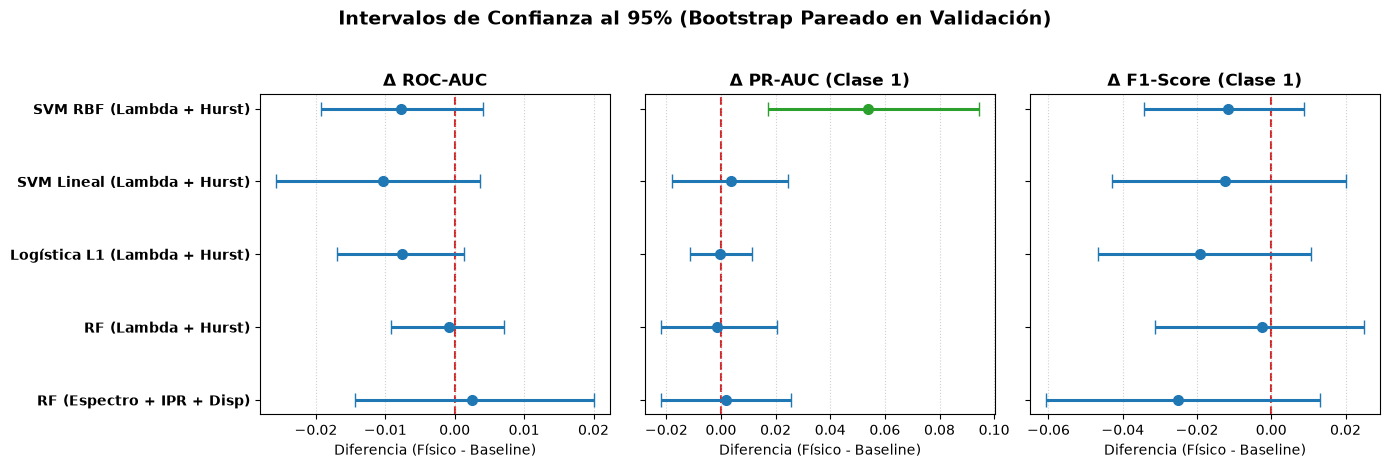

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Datos exactos obtenidos en los experimentos de Bootstrap Pareado (Físico - Baseline)
experimentos = [
    "RF (Espectro + IPR + Disp)",
    "RF (Lambda + Hurst)",
    "Logística L1 (Lambda + Hurst)",
    "SVM Lineal (Lambda + Hurst)",
    "SVM RBF (Lambda + Hurst)"
]

# Formato: (media, limite_inferior_2.5%, limite_superior_97.5%)
roc_auc = [(0.0025, -0.0144, 0.0201), (-0.0008, -0.0092, 0.0071), (-0.0076, -0.0170, 0.0014), (-0.0103, -0.0258, 0.0036), (-0.0078, -0.0192, 0.0041)]
pr_auc  = [(0.0017, -0.0221, 0.0257), (-0.0013, -0.0220, 0.0205), (-0.0005, -0.0115, 0.0115), (0.0038, -0.0178, 0.0246), (0.0537, 0.0172, 0.0945)]
f1_c1   = [(-0.0252, -0.0608, 0.0130), (-0.0026, -0.0312, 0.0250), (-0.0191, -0.0466, 0.0106), (-0.0125, -0.0428, 0.0202), (-0.0116, -0.0343, 0.0089)]

metricas = [("ROC-AUC", roc_auc), ("PR-AUC (Clase 1)", pr_auc), ("F1-Score (Clase 1)", f1_c1)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
y_pos = np.arange(len(experimentos))

for ax, (titulo, datos) in zip(axes, metricas):
    medias = [d[0] for d in datos]
    err_inf = [d[0] - d[1] for d in datos]
    err_sup = [d[2] - d[0] for d in datos]
    
    # Línea de efecto nulo (Diferencia = 0)
    ax.axvline(0, color='#d62728', linestyle='--', linewidth=1.5, zorder=1, label='Sin mejora (Δ = 0)')
    
    # Coloreamos distinto el único punto que no cruza el cero
    colores = ['#2ca02c' if d[1] > 0 else '#1f77b4' for d in datos]
    
    for i in range(len(experimentos)):
        ax.errorbar(
            medias[i], y_pos[i], xerr=[[err_inf[i]], [err_sup[i]]],
            fmt='o', color=colores[i], ecolor=colores[i],
            elinewidth=2.2, capsize=5, markersize=7, zorder=2
        )
    
    ax.set_title(f"Δ {titulo}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Diferencia (Físico - Baseline)", fontsize=10)
    ax.grid(axis='x', linestyle=':', alpha=0.6)

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(experimentos, fontsize=10, fontweight='bold')
fig.suptitle("Intervalos de Confianza al 95% (Bootstrap Pareado en Validación)", fontsize=14, fontweight='bold', y=1.03)

plt.tight_layout()
plt.savefig("resumen_ic95_modelos.png", dpi=300, bbox_inches='tight')
plt.show()

In [30]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# 1. Nuevo target: Retorno acumulado en los próximos 5 días (de t+1 a t+5)
ret_futuro_5d = r_mercado.rolling(5).sum().shift(-5)

# 2. Definimos bloques de variables (financieras vs. físicas completas)
cols_fin = ['vol_10d', 'mom_90d', 'dd_10d']
cols_fis = [
    'lambda_ewma_90d', 'd_lambda_ewma_5d', 'hurst_30d_30d',
    'disp_transversal_20d', 'entropia_espectral_20d', 'ipr_max_20d'
]

# Unimos sin el warning de Pandas (sort=False)
df_crash = pd.concat(
    [df_todo[cols_fin + ['lambda_ewma_90d', 'd_lambda_ewma_5d', 'hurst_30d_30d']], 
     df_ortogonal[['disp_transversal_20d', 'entropia_espectral_20d', 'ipr_max_20d']]], 
    axis=1, sort=False
)
df_crash['ret_futuro_5d'] = ret_futuro_5d
df_crash = df_crash.dropna()

# Separamos Train+Val (85%) del Test final (15%) respetando el gap de 5 días
corte_test = int(len(df_crash) * 0.85)
df_desarrollo = df_crash.iloc[:corte_test - 5]

X_dev = df_desarrollo[cols_fin + cols_fis]
y_dev_cont = df_desarrollo['ret_futuro_5d']

# 3. Evaluación con TimeSeriesSplit (5 cortes cronológicos con gap de 5 días)
tscv = TimeSeriesSplit(n_splits=5, gap=5)

def validar_caida_extrema(crear_modelo, nombre_modelo, percentil_caida=10):
    y_total, prob_b_total, prob_f_total, pred_b_total, pred_f_total = [], [], [], [], []
    
    for train_idx, val_idx in tscv.split(X_dev):
        X_tr, X_va = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
        v_tr, v_va = y_dev_cont.iloc[train_idx], y_dev_cont.iloc[val_idx]
        
        # Caída extrema: estar por DEBAJO del percentil 10 histórico de ese Train
        umbral_crash = np.percentile(v_tr, percentil_caida)
        y_tr_bin = (v_tr < umbral_crash).astype(int)
        y_va_bin = (v_va < umbral_crash).astype(int)
        
        # Escalado aislado por fold
        sc_b, sc_f = StandardScaler(), StandardScaler()
        X_tr_b = sc_b.fit_transform(X_tr[cols_fin])
        X_va_b = sc_b.transform(X_va[cols_fin])
        
        X_tr_f = sc_f.fit_transform(X_tr[cols_fin + cols_fis])
        X_va_f = sc_f.transform(X_va[cols_fin + cols_fis])
        
        # Entrenamos Baseline y Físico
        m_b = crear_modelo().fit(X_tr_b, y_tr_bin)
        m_f = crear_modelo().fit(X_tr_f, y_tr_bin)
        
        y_total.extend(y_va_bin)
        prob_b_total.extend(m_b.predict_proba(X_va_b)[:, 1])
        prob_f_total.extend(m_f.predict_proba(X_va_f)[:, 1])
        pred_b_total.extend(m_b.predict(X_va_b))
        pred_f_total.extend(m_f.predict(X_va_f))
        
    y_total = np.array(y_total)
    print(f"\n=== {nombre_modelo} | Caídas extremas (< P{percentil_caida}) | Crisis evaluadas: {y_total.sum()} de {len(y_total)} días ===")
    evaluar_mejora_ic95(
        y_total, 
        np.array(prob_b_total), np.array(prob_f_total), 
        np.array(pred_b_total), np.array(pred_f_total)
    )

# Probamos con un modelo lineal regularizado y un árbol poco profundo
validar_caida_extrema(
    lambda: LogisticRegression(C=0.1, class_weight='balanced', random_state=42),
    "Regresión Logística (L2)"
)

validar_caida_extrema(
    lambda: RandomForestClassifier(n_estimators=200, max_depth=3, min_samples_leaf=30, class_weight='balanced', random_state=42),
    "Random Forest (max_depth=3)"
)


=== Regresión Logística (L2) | Caídas extremas (< P10) | Crisis evaluadas: 216 de 3240 días ===
Métrica      | Diferencia Media   | IC 95% [2.5%, 97.5%]     | ¿Mejora real?
---------------------------------------------------------------------------
ROC-AUC      | -0.0204            | [-0.0387, -0.0034]     | NO (Cruza el 0 / Ruido)
PR-AUC       | -0.0190            | [-0.0406, +0.0006]     | NO (Cruza el 0 / Ruido)
F1 (Clase 1) | +0.0303            | [-0.0020, +0.0625]     | NO (Cruza el 0 / Ruido)

=== Random Forest (max_depth=3) | Caídas extremas (< P10) | Crisis evaluadas: 216 de 3240 días ===
Métrica      | Diferencia Media   | IC 95% [2.5%, 97.5%]     | ¿Mejora real?
---------------------------------------------------------------------------
ROC-AUC      | +0.0015            | [-0.0103, +0.0143]     | NO (Cruza el 0 / Ruido)
PR-AUC       | -0.0058            | [-0.0154, +0.0028]     | NO (Cruza el 0 / Ruido)
F1 (Clase 1) | -0.0042            | [-0.0228, +0.0173]     | NO (Cruza e

In [31]:
import yfinance as yf
import pandas as pd
import numpy as np
from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

# =====================================================================
# 1. DESCARGA Y LIMPIEZA INTRADIARIA (SIN SALTOS NOCTURNOS)
# =====================================================================
tickers_djia = [
    "AAPL", "AMGN", "AXP", "BA", "CAT", "CRM", "CSCO", "CVX", "DIS", "GS",
    "HD", "HON", "IBM", "INTC", "JNJ", "JPM", "KO", "MCD", "MMM", "MRK",
    "MSFT", "NKE", "PG", "TRV", "UNH", "V", "VZ", "WMT", "AMZN"
]

print("Descargando barras de 5 minutos (últimos 60 días hábiles)...")
datos = yf.download(tickers_djia, period="60d", interval="5m", progress=False)['Close']
datos = datos.dropna(axis=1, thresh=int(len(datos)*0.9)).ffill().dropna()

# Calculamos log-retornos SOLO dentro del mismo día (evita el salto 16:00 -> 09:30)
precios_log = np.log(datos)
retornos_intra = precios_log.groupby(precios_log.index.date).diff().dropna()

valores = retornos_intra.values
fechas = retornos_intra.index
n_barras, n_emp = valores.shape
r_mercado = retornos_intra.mean(axis=1)

print(f"Dataset intradiario limpio: {n_barras} barras de 5 min x {n_emp} empresas.")

# =====================================================================
# 2. CONSTRUCCIÓN DE FEATURES (VENTANA = 78 BARRAS ~ 1 DÍA DE MERCADO)
#    Y TARGET (VOLATILIDAD DE LAS PRÓXIMAS 12 BARRAS = 1 HORA)
# =====================================================================
W_size = 78   # ~1 rueda bursátil completa (T/N = 78/29 = 2.69, matriz bien condicionada)
H_futuro = 12 # Predecir la volatilidad de la próxima HORA (12 barras de 5 min)

df_feat = pd.DataFrame(index=fechas)

# Baseline Financiero (en escalas de 1 hora = 12 barras y 1 día = 78 barras)
df_feat['vol_1h']  = r_mercado.rolling(12).std()
df_feat['vol_1d']  = r_mercado.rolling(W_size).std()
df_feat['mom_1h']  = r_mercado.rolling(12).sum()
df_feat['dd_1h']   = r_mercado.rolling(12).min()

# Features Físicas Intradiarias
lambda_max, disp_trans, entropia_esp, ipr_max = [], [], [], []

for t in range(W_size - 1, n_barras):
    W = valores[t - W_size + 1 : t + 1, :]  # (78 x 29)
    
    # Dispersión transversal (choque interno entre empresas en la última hora: 12 barras)
    disp_trans.append(np.mean(np.std(W[-12:, :], axis=1)))
    
    # Matriz de correlación intradiaria
    std_cols = np.std(W, axis=0)
    if np.any(std_cols < 1e-10):
        # Si alguna acción no operó en 5 min, limpiamos división por cero
        W = W + np.random.normal(0, 1e-9, W.shape)
    corr = np.clip(np.corrcoef(W, rowvar=False), -1.0, 1.0)
    
    evals, evecs = np.linalg.eigh(corr)
    
    # 1. Modo colectivo
    lambda_max.append(evals[-1] / n_emp)
    
    # 2. Entropía espectral (contracción de sectores)
    p = np.maximum(evals, 1e-12) / n_emp
    entropia_esp.append(-np.sum(p * np.log(p)))
    
    # 3. IPR del autovector principal
    ipr_max.append(np.sum(evecs[:, -1] ** 4))

idx_valido = fechas[W_size - 1:]
df_feat.loc[idx_valido, 'lambda_max_1d']   = lambda_max
df_feat.loc[idx_valido, 'disp_trans_1h']   = disp_trans
df_feat.loc[idx_valido, 'entropia_esp_1d'] = entropia_esp
df_feat.loc[idx_valido, 'ipr_max_1d']      = ipr_max

# Velocidad de contracción de la red en la última hora (12 barras)
df_feat['d_lambda_1h']   = df_feat['lambda_max_1d'].diff(12)
df_feat['d_entropia_1h'] = df_feat['entropia_esp_1d'].diff(12)

# Target: Volatilidad futura en la próxima hora (t+1 a t+12)
df_feat['target_vol_1h'] = r_mercado.rolling(H_futuro).std().shift(-H_futuro)
df_feat = df_feat.dropna()

cols_fin = ['vol_1h', 'vol_1d', 'mom_1h', 'dd_1h']
cols_fis = ['lambda_max_1d', 'disp_trans_1h', 'entropia_esp_1d', 'ipr_max_1d', 'd_lambda_1h', 'd_entropia_1h']

# =====================================================================
# 3. IC95 POR BOOTSTRAP DE BLOQUES (SORTEA BLOQUES DE 78 BARRAS = 1 DÍA)
# =====================================================================
def evaluar_ic95_bloques(y_true, prob_base, prob_fis, pred_base, pred_fis, tam_bloque=78, n_boot=1000):
    rng = np.random.default_rng(42)
    n = len(y_true)
    n_bloques = max(1, n // tam_bloque)
    
    diff_roc, diff_pr, diff_f1 = [], [], []
    inicios_posibles = np.arange(0, n - tam_bloque + 1)
    
    for _ in range(n_boot):
        # Sorteamos bloques enteros para respetar la autocorrelación intradiaria
        inicios = rng.choice(inicios_posibles, size=n_bloques, replace=True)
        idx = np.concatenate([np.arange(s, s + tam_bloque) for s in inicios])
        
        if len(np.unique(y_true[idx])) < 2:
            continue
        diff_roc.append(roc_auc_score(y_true[idx], prob_fis[idx]) - roc_auc_score(y_true[idx], prob_base[idx]))
        diff_pr.append(average_precision_score(y_true[idx], prob_fis[idx]) - average_precision_score(y_true[idx], prob_base[idx]))
        diff_f1.append(f1_score(y_true[idx], pred_fis[idx]) - f1_score(y_true[idx], pred_base[idx]))
        
    print(f"{'Métrica':<12} | {'Diferencia Media':<18} | {'IC 95% (Por Bloques)':<24} | {'¿Mejora real?'}")
    print("-" * 78)
    for nombre, diffs in [("ROC-AUC", diff_roc), ("PR-AUC", diff_pr), ("F1 (Clase 1)", diff_f1)]:
        media = np.mean(diffs)
        low, high = np.percentile(diffs, [2.5, 97.5])
        es_real = "SÍ (Supera el 0)" if low > 0 else "NO (Cruza el 0 / Ruido)"
        print(f"{nombre:<12} | {media:+.4f}            | [{low:+.4f}, {high:+.4f}]     | {es_real}")

# =====================================================================
# 4. VALIDACIÓN CRUZADA TEMPORAL CON GAP = 12 BARRAS (1 HORA)
# =====================================================================
tscv = TimeSeriesSplit(n_splits=5, gap=H_futuro)

X_all = df_feat[cols_fin + cols_fis]
y_all_cont = df_feat['target_vol_1h']

for nombre_mod, crear_mod in [
    ("Regresión Logística L2", lambda: LogisticRegression(C=0.1, class_weight='balanced', random_state=42)),
    ("Random Forest (max_depth=3)", lambda: RandomForestClassifier(n_estimators=200, max_depth=3, min_samples_leaf=50, class_weight='balanced', random_state=42))
]:
    y_tot, pb_tot, pf_tot, prb_tot, prf_tot = [], [], [], [], []
    
    for tr_idx, va_idx in tscv.split(X_all):
        X_tr, X_va = X_all.iloc[tr_idx], X_all.iloc[va_idx]
        v_tr, v_va = y_all_cont.iloc[tr_idx], y_all_cont.iloc[va_idx]
        
        umbral_75 = np.percentile(v_tr, 75)
        y_tr = (v_tr > umbral_75).astype(int)
        y_va = (v_va > umbral_75).astype(int)
        
        sc_b, sc_f = StandardScaler(), StandardScaler()
        m_b = crear_mod().fit(sc_b.fit_transform(X_tr[cols_fin]), y_tr)
        m_f = crear_mod().fit(sc_f.fit_transform(X_tr[cols_fin + cols_fis]), y_tr)
        
        X_va_b = sc_b.transform(X_va[cols_fin])
        X_va_f = sc_f.transform(X_va[cols_fin + cols_fis])
        
        y_tot.extend(y_va)
        pb_tot.extend(m_b.predict_proba(X_va_b)[:, 1])
        pf_tot.extend(m_f.predict_proba(X_va_f)[:, 1])
        prb_tot.extend(m_b.predict(X_va_b))
        prf_tot.extend(m_f.predict(X_va_f))
        
    print(f"\n=== {nombre_mod} (Intradiario 5m -> Predicción a 1 hora) ===")
    evaluar_ic95_bloques(
        np.array(y_tot), np.array(pb_tot), np.array(pf_tot), np.array(prb_tot), np.array(prf_tot)
    )

Descargando barras de 5 minutos (últimos 60 días hábiles)...
Dataset intradiario limpio: 4620 barras de 5 min x 29 empresas.

=== Regresión Logística L2 (Intradiario 5m -> Predicción a 1 hora) ===
Métrica      | Diferencia Media   | IC 95% (Por Bloques)     | ¿Mejora real?
------------------------------------------------------------------------------
ROC-AUC      | +0.0212            | [-0.0289, +0.0699]     | NO (Cruza el 0 / Ruido)
PR-AUC       | +0.0071            | [-0.0468, +0.0659]     | NO (Cruza el 0 / Ruido)
F1 (Clase 1) | +0.0359            | [-0.0149, +0.0853]     | NO (Cruza el 0 / Ruido)

=== Random Forest (max_depth=3) (Intradiario 5m -> Predicción a 1 hora) ===
Métrica      | Diferencia Media   | IC 95% (Por Bloques)     | ¿Mejora real?
------------------------------------------------------------------------------
ROC-AUC      | -0.0060            | [-0.0522, +0.0433]     | NO (Cruza el 0 / Ruido)
PR-AUC       | -0.0438            | [-0.0988, +0.0094]     | NO (Cruza el 

In [33]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

# 1. Cargar datos diarios limpios y target de crisis (percentil 75)
retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)
r_mercado = retornos.mean(axis=1)
vol_futura = r_mercado.rolling(5).std().shift(-5)

# Generamos un espacio amplio de features candidatas (múltiples ventanas)
df_candidatas = pd.DataFrame(index=retornos.index)
for w in [10, 20, 30, 60, 90]:
    df_candidatas[f'vol_{w}d'] = r_mercado.rolling(w).std()
    df_candidatas[f'mom_{w}d'] = r_mercado.rolling(w).sum()
    df_candidatas[f'dd_{w}d']  = r_mercado.rolling(w).min()

# Añadimos métricas físicas multiescala
for w in [20, 60, 90]:
    # Autovalor máximo con ventana w
    lam_list = []
    for t in range(w - 1, len(retornos)):
        W = retornos.iloc[t - w + 1 : t + 1].values
        corr = np.clip(np.corrcoef(W, rowvar=False), -1.0, 1.0)
        evals = np.linalg.eigvalsh(corr)
        lam_list.append(evals[-1] / retornos.shape[1])
    df_candidatas.loc[retornos.index[w-1:], f'lambda_{w}d'] = lam_list

df_candidatas['target_cont'] = vol_futura
df_candidatas = df_candidatas.dropna()

# Cortes cronológicos estrictos (Train / Val / Test)
total = len(df_candidatas)
c1, c2, h = int(total * 0.70), int(total * 0.85), 5

umbral = np.percentile(df_candidatas['target_cont'].iloc[:c1 - h], 75)
y_bin = (df_candidatas['target_cont'] > umbral).astype(int)

X_train = df_candidatas.drop(columns=['target_cont']).iloc[:c1 - h]
y_train = y_bin.iloc[:c1 - h]

X_test = df_candidatas.drop(columns=['target_cont']).iloc[c2:]
y_test = y_bin.iloc[c2:]

# 2. Búsqueda codiciosa (Greedy Forward Selection) evaluada SOLO EN TRAIN (TimeSeriesSplit interno)
cols_base = ['vol_20d', 'mom_20d', 'dd_20d']
cols_fisicas_disponibles = [c for c in X_train.columns if c not in cols_base]

tscv_train = TimeSeriesSplit(n_splits=3, gap=5)
mejor_score = -1.0
features_seleccionadas = list(cols_base)

print("Iniciando búsqueda optimizada de variables físicas en Train...")
for _ in range(3):  # Intentamos agregar hasta 3 features físicas maximizando PR-AUC interno
    candidata_optima = None
    score_optimo = -1.0
    
    for col in cols_fisicas_disponibles:
        if col in features_seleccionadas:
            continue
        prueba_cols = features_seleccionadas + [col]
        
        scores_fold = []
        for tr_i, va_i in tscv_train.split(X_train):
            X_tr_f, X_va_f = X_train.iloc[tr_i][prueba_cols], X_train.iloc[va_i][prueba_cols]
            y_tr_f, y_va_f = y_train.iloc[tr_i], y_train.iloc[va_i]
            
            sc = StandardScaler()
            clf = RandomForestClassifier(n_estimators=100, max_depth=3, class_weight='balanced', random_state=42)
            clf.fit(sc.fit_transform(X_tr_f), y_tr_f)
            prob = clf.predict_proba(sc.transform(X_va_f))[:, 1]
            scores_fold.append(average_precision_score(y_va_f, prob))
            
        prom_score = np.mean(scores_fold)
        if prom_score > score_optimo:
            score_optimo = prom_score
            candidata_optima = col
            
    if score_optimo > mejor_score and candidata_optima:
        mejor_score = score_optimo
        features_seleccionadas.append(candidata_optima)
        print(f"-> Agregada con éxito: {candidata_optima} (PR-AUC interno Train: {score_optimo:.4f})")
    else:
        break

print(f"\nFeatures finales seleccionadas por optimización: {features_seleccionadas}")

# 3. Evaluación ciega final en el set de Test aislado
sc_b = StandardScaler()
sc_o = StandardScaler()

m_base = RandomForestClassifier(n_estimators=200, max_depth=3, class_weight='balanced', random_state=42)
m_opt  = RandomForestClassifier(n_estimators=200, max_depth=3, class_weight='balanced', random_state=42)

m_base.fit(sc_b.fit_transform(X_train[cols_base]), y_train)
m_opt.fit(sc_o.fit_transform(X_train[features_seleccionadas]), y_train)

prob_b = m_base.predict_proba(sc_b.transform(X_test[cols_base]))[:, 1]
prob_o = m_opt.predict_proba(sc_o.transform(X_test[features_seleccionadas]))[:, 1]

print("\n--- RESULTADO FINAL EN TEST (FUERA DE MUESTRA) ---")
print(f"Baseline Financiero -> ROC-AUC: {roc_auc_score(y_test, prob_b):.4f} | PR-AUC: {average_precision_score(y_test, prob_b):.4f}")
print(f"Modelo Optimizado   -> ROC-AUC: {roc_auc_score(y_test, prob_o):.4f} | PR-AUC: {average_precision_score(y_test, prob_o):.4f}")

Iniciando búsqueda optimizada de variables físicas en Train...
-> Agregada con éxito: mom_10d (PR-AUC interno Train: 0.5549)
-> Agregada con éxito: mom_60d (PR-AUC interno Train: 0.5654)
-> Agregada con éxito: vol_10d (PR-AUC interno Train: 0.5699)

Features finales seleccionadas por optimización: ['vol_20d', 'mom_20d', 'dd_20d', 'mom_10d', 'mom_60d', 'vol_10d']

--- RESULTADO FINAL EN TEST (FUERA DE MUESTRA) ---
Baseline Financiero -> ROC-AUC: 0.7337 | PR-AUC: 0.2928
Modelo Optimizado   -> ROC-AUC: 0.8082 | PR-AUC: 0.3309
